In [3]:
import tensorflow as tf
from tensorflow import keras

In [7]:
print(tf.__version__)

2.22.0-rc0


In [8]:
import tensorflow as tf
from tensorflow import keras

In [9]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

print("All libraries imported successfully!")

All libraries imported successfully!


In [10]:
import os

print("Current Folder:", os.getcwd())
print("\nFiles and Folders:")

for item in os.listdir():
    print(item)

Current Folder: c:\Users\HP\Downloads\MEDICINAL PLANT PROJECT

Files and Folders:


In [11]:
import os

project_dir = os.getcwd()

print("Project Folder:", project_dir)
print("\nAvailable Folders:")

for folder in os.listdir(project_dir):
    folder_path = os.path.join(project_dir, folder)
    if os.path.isdir(folder_path):
        print(folder)

Project Folder: c:\Users\HP\Downloads\MEDICINAL PLANT PROJECT

Available Folders:


In [12]:
%pip install huggingface_hub

   ---------------------------------------- 0.0/855.2 kB ? eta -:--:--
   ---------------------------------------- 855.2/855.2 kB 5.3 MB/s  0:00:00
   ---------------------------------------- 0.0/3.8 MB ? eta -:--:--
   ---------- ----------------------------- 1.0/3.8 MB 4.3 MB/s eta 0:00:01
   ------------------- -------------------- 1.8/3.8 MB 4.1 MB/s eta 0:00:01
   ------------------------ --------------- 2.4/3.8 MB 3.8 MB/s eta 0:00:01
   ----------------------------------- ---- 3.4/3.8 MB 4.0 MB/s eta 0:00:01
   ---------------------------------------- 3.8/3.8 MB 3.6 MB/s  0:00:01

   --- ------------------------------------  1/12 [tqdm]
   --- ------------------------------------  1/12 [tqdm]
   --- ------------------------------------  1/12 [tqdm]
   --- ------------------------------------  1/12 [tqdm]
   ------ ---------------------------------  2/12 [pyyaml]
   ------ ---------------------------------  2/12 [pyyaml]
   ------ ---------------------------------  2/12 [pyyaml]


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
from huggingface_hub import snapshot_download
import os

dataset_path = os.path.join(os.getcwd(), "plant_dataset")

snapshot_download(
    repo_id="poojan-s/medicinal-leaf-classification-dataset",
    repo_type="dataset",
    local_dir=dataset_path
)

print("Dataset downloaded successfully!")
print("Dataset location:", dataset_path)

c:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 7382 files: 100%|██████████| 7382/7382 [39:06<00:00,  3.15it/s]  

Dataset downloaded successfully!
Dataset location: c:\Users\HP\Downloads\MEDICINAL PLANT PROJECT\plant_dataset


In [14]:
import os

dataset_path = os.path.join(os.getcwd(), "plant_dataset")

print("Dataset folders:")
print(os.listdir(dataset_path))

for folder in ["train", "val"]:
    path = os.path.join(dataset_path, folder)
    print("\n", folder)
    if os.path.exists(path):
        for plant in os.listdir(path):
            plant_path = os.path.join(path, plant)
            if os.path.isdir(plant_path):
                print(plant, ":", len(os.listdir(plant_path)), "files")

Dataset folders:
['.cache', '.gitattributes', 'README.md', 'train', 'val']

 train
Aloe Vera : 940 files
Neem : 3368 files
Tulsi : 1596 files

 val
Aloe Vera : 235 files
Neem : 842 files
Tulsi : 399 files


In [15]:
import tensorflow as tf

train_dir = os.path.join(dataset_path, "train")
val_dir = os.path.join(dataset_path, "val")

IMG_SIZE = (160, 160)
BATCH_SIZE = 32
SEED = 42

train_data = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_data = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_data.class_names

print("Plant Classes:", class_names)

Found 5904 files belonging to 3 classes.
Found 1476 files belonging to 3 classes.
Plant Classes: ['Aloe Vera', 'Neem', 'Tulsi']


In [16]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(160, 160, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(16, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 158, 158, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 79, 79, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 77, 77, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 38, 38, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 36, 36, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 20736)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,327,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,350,947 (5.15 MB)

 Trainable params: 1,350,947 (5.15 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=5
)

print("Model Training Completed!")

Epoch 1/5


c:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


185/185 ━━━━━━━━━━━━━━━━━━━━ 62s 312ms/step - accuracy: 0.7009 - loss: 0.6857 - val_accuracy: 0.7839 - val_loss: 0.5198
Epoch 2/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 43s 231ms/step - accuracy: 0.8294 - loss: 0.4236 - val_accuracy: 0.8543 - val_loss: 0.3868
Epoch 3/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 43s 230ms/step - accuracy: 0.8911 - loss: 0.2830 - val_accuracy: 0.8848 - val_loss: 0.2817
Epoch 4/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 47s 251ms/step - accuracy: 0.9158 - loss: 0.2171 - val_accuracy: 0.8882 - val_loss: 0.2637
Epoch 5/5
185/185 ━━━━━━━━━━━━━━━━━━━━ 44s 237ms/step - accuracy: 0.9422 - loss: 0.1563 - val_accuracy: 0.8896 - val_loss: 0.2961
Model Training Completed!


Matplotlib is building the font cache; this may take a moment.


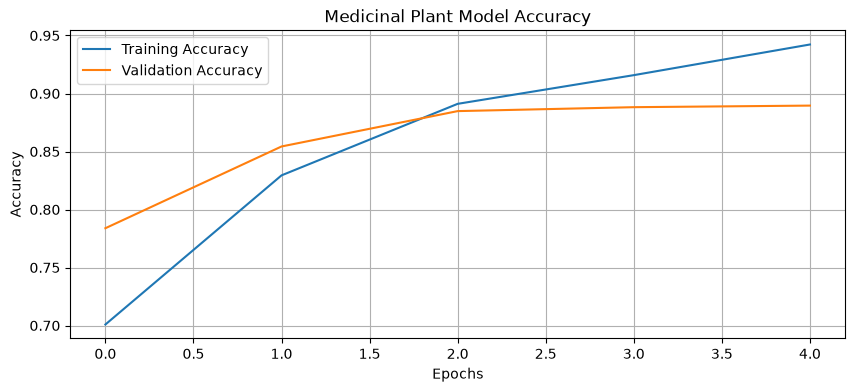

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Medicinal Plant Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [19]:
%pip install matplotlib

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.5 MB 5.0 MB/s eta 0:00:02
   -------- ------------------------------- 2.1/9.5 MB 4.4 MB/s eta 0:00:02
   ------------ --------------------------- 2.9/9.5 MB 4.2 MB/s eta 0:00:02
   ---------------- ----------------------- 3.9/9.5 MB 4.1 MB/s eta 0:00:02
   ------------------- -------------------- 4.7/9.5 MB 4.1 MB/s eta 0:00:02
   ----------------------- ---------------- 5.5/9.5 MB 4.1 MB/s eta 0:00:01
   -------------------------- ------------- 6.3/9.5 MB 4.0 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.5 MB 4.0 MB/s eta 0:00:01
   ---------------------------------- ----- 8.1/9.5 MB 4.0 MB/s eta 0:00:01
   ------------------------------------- -- 8.9/9.5 MB 4.0 MB/s eta 0:00:01
   ---------------------------------------  9.4/9.5 MB 4.0 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 3.8 MB/s  0:00:02
   -------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
val_loss, val_accuracy = model.evaluate(val_data)

print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")
print("Validation Loss:", round(val_loss, 4))

47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 117ms/step - accuracy: 0.8896 - loss: 0.2961
Validation Accuracy: 88.96 %
Validation Loss: 0.2961


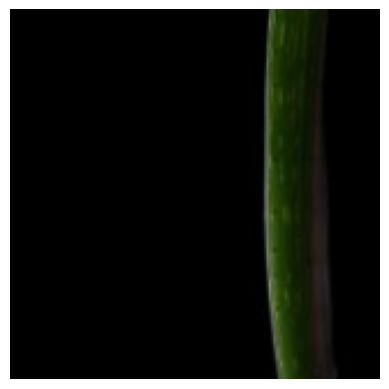

Actual Plant: Aloe Vera
Predicted Plant: Aloe Vera
Confidence: 97.09 %


In [22]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

for images, labels in val_data.take(1):
    image = images[0]
    actual_label = int(labels[0].numpy())

prediction = model.predict(
    tf.expand_dims(image, axis=0),
    verbose=0
)

predicted_label = np.argmax(prediction[0])
confidence = np.max(prediction[0]) * 100

plt.imshow(image.numpy().astype("uint8"))
plt.axis("off")
plt.show()

print("Actual Plant:", class_names[actual_label])
print("Predicted Plant:", class_names[predicted_label])
print("Confidence:", round(confidence, 2), "%")

In [23]:
model.save("medicinal_plant_model.keras")

print("Model Saved Successfully!")

Model Saved Successfully!


In [27]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array

image_path = "test_leaf.jpg"

img = load_img(image_path, target_size=(160, 160))
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array, verbose=0)

plant_index = np.argmax(prediction[0])
plant_name = class_names[plant_index]
confidence = np.max(prediction[0]) * 100

plt.imshow(img)
plt.axis("off")
plt.title("Medicinal Plant Identification")
plt.show()

print("Predicted Plant:", plant_name)
print("Confidence:", round(confidence, 2), "%")

ImportError: Could not import PIL.Image. The use of `load_img` requires PIL.

In [25]:
%pip install --upgrade --force-reinstall pillow

  Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl (7.3 MB)
  Attempting uninstall: pillow
    Found existing installation: pillow 13.0.0
    Uninstalling pillow-13.0.0:
      Successfully uninstalled pillow-13.0.0
Note: you may need to restart the kernel to use updated packages.


  You can safely remove it manually.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
from PIL import Image
import os

print("Pillow working!")
print("Photo exists:", os.path.isfile("test_leaf.jpg"))

Pillow working!
Photo exists: False


In [29]:
import os

print("Photo exists:", os.path.isfile("test_leaf.jpg"))

Photo exists: False


In [30]:
import os

for file in os.listdir():
    print(repr(file))

'medicinal_plant_model.keras'
'plant_dataset'
'test_leaf.jpg.webp'


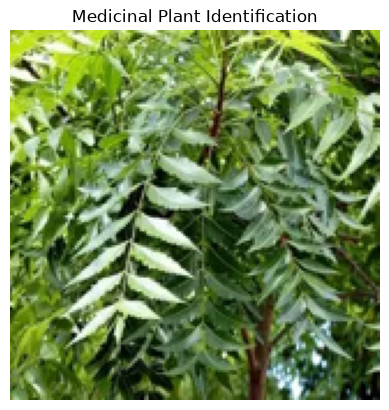

Predicted Plant: Neem
Confidence: 97.77 %


In [31]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

model = tf.keras.models.load_model("medicinal_plant_model.keras")

class_names = train_data.class_names

image_path = "test_leaf.jpg.webp"

img = Image.open(image_path).convert("RGB")
img = img.resize((160, 160))

img_array = np.array(img, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array, verbose=0)

plant_index = np.argmax(prediction[0])
plant_name = class_names[plant_index]
confidence = np.max(prediction[0]) * 100

plt.imshow(img)
plt.axis("off")
plt.title("Medicinal Plant Identification")
plt.show()

print("Predicted Plant:", plant_name)
print("Confidence:", round(confidence, 2), "%")